In [ ]:
import pandas as pd

In [ ]:
crop_df = pd.read_csv(r"D:\Downloads\crop_yield.csv")

In [ ]:
crop_df

In [ ]:
crop_df.head(10)

In [5]:
crop_df.isnull().sum()
print (crop_df.isnull().sum())

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64


In [6]:
crop_df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [7]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [8]:
crop_df.dropna (subset=['YIELD_KG'])

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
...,...,...,...,...,...,...,...,...,...
2995,F2996,Wheat,1500.0,NaN,15/03/2031,NaN,Rabi,Yes,30000
2996,F2997,Rice,2000.0,3.0,16/03/2031,Lahore,Rabi,Yes,40000
2997,F2998,Sugarcane,2000.0,5.0,17/03/2031,Lahore,Rabi,Yes,40000
2998,F2999,Sugarcane,2000.0,NaN,18/03/2031,Lahore,Rabi,NaN,40000


In [9]:
crop_df['AREA_ACRES'].fillna (crop_df['AREA_ACRES'].mean())

0       4.000000
1       5.000000
2       5.000000
3       4.420168
4       4.000000
          ...   
2995    4.420168
2996    3.000000
2997    5.000000
2998    4.420168
2999    3.000000
Name: AREA_ACRES, Length: 3000, dtype: float64

In [10]:
crop_df['DISTRICT'].fillna('unknown')

0          Sialkot
1           Multan
2       Faisalabad
3           Multan
4       Faisalabad
           ...    
2995       unknown
2996        Lahore
2997        Lahore
2998        Lahore
2999    Faisalabad
Name: DISTRICT, Length: 3000, dtype: str

In [11]:
crop_df['FERTILIZER_USED'].fillna('no')

0       Yes
1        No
2       Yes
3       Yes
4        No
       ... 
2995    Yes
2996    Yes
2997    Yes
2998     no
2999     No
Name: FERTILIZER_USED, Length: 3000, dtype: str

In [13]:
crop_df['YIELD_VALUE'].fillna (crop_df['YIELD_VALUE'].mean())

0       30000
1       30000
2       50000
3       30000
4       30000
        ...  
2995    30000
2996    40000
2997    40000
2998    40000
2999    50000
Name: YIELD_VALUE, Length: 3000, dtype: int64

In [21]:
crop_df['HARVEST_DATE'] = pd.to_datetime(crop_df['HARVEST_DATE'], errors='coerce', format='%d/%m/%Y')

In [22]:
crop_df['HARVEST_DATE'].head()
crop_df.dtypes

FARM_ID                       str
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [28]:
crop_df['FARM_ID'].head()
crop_df['FARM_ID'].dtype   #alreday Farm ID is integer type.there is no need to convert it into integer again.

dtype('int64')

#alreday Farm ID is integer type.there is no need to convert it into integer again.

In [29]:
crop_df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [33]:
crop_df.dtypes

FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [42]:
yield_by_crop = crop_df.groupby('CROP_TYPE').agg({'YIELD_KG': 'sum'})
print 

0      2023-01-01
1      2023-01-02
2      2023-01-03
3      2023-01-04
4      2023-01-05
          ...    
2995   2031-03-15
2996   2031-03-16
2997   2031-03-17
2998   2031-03-18
2999   2031-03-19
Name: HARVEST_DATE, Length: 3000, dtype: datetime64[us]

In [43]:
import matplotlib.pyplot as plt

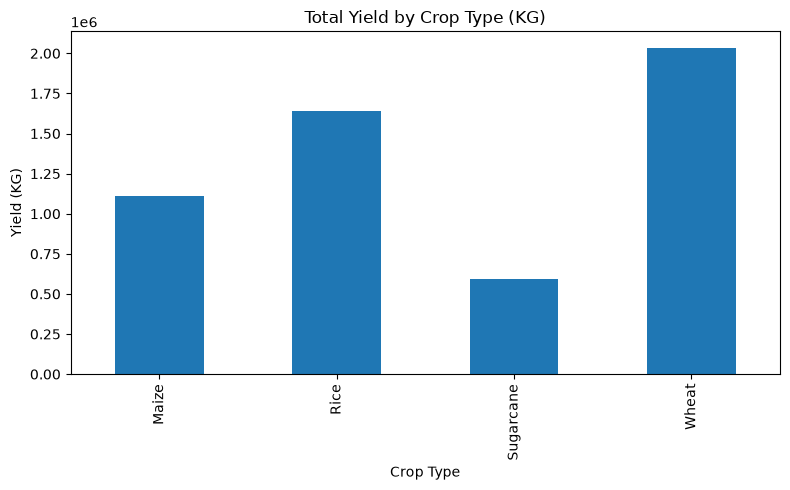

In [52]:
yield_by_crop.plot(kind="bar", legend=False, figsize=(8, 5))
plt.title("Total Yield by Crop Type (KG)")
plt.ylabel("Yield (KG)")
plt.xlabel("Crop Type")
plt.tight_layout()
plt.savefig("total_yield_by_crop.png")
plt.show()

In [58]:
yield_pivot = crop_df.pivot_table(values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum")
print(yield_pivot)

TypeError: 'Series' object is not callable